# 06 · Independent validation

Written as a model validation team would test a stress-testing model before it is used for capital (PRA SS1/23 principle 4: *model validation*). The question is not "does it fit?" but **"would it have worked, and how wrong could it be?"**

| Test | Question |
|---|---|
| 1. Out-of-time backtests | Re-estimated before a crisis, given the economy that actually followed, does the model project the losses that happened? |
| 2. Live monitoring since the 2024 Q4 jump-off | How has the model performed on the quarters since the scenario start date? |
| 3. Rolling-origin forecasts vs a naive benchmark | Is the model better than assuming "losses stay where they are"? |
| 4. Selection-honest backtest | Would the *selection procedure*, run in 2007, have chosen a model that worked in 2008? |
| 5. Block-bootstrap parameter uncertainty | Are the Newey–West intervals believable? |
| 6. Quantile regression | Do tail losses respond more strongly to the economy than the median? |
| 7. Sensitivity analysis | How much does each driver move projected losses? |
| 8. Challenger models | How much do projections depend on the choice of model? |

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

from ukstress.config import MODELS_DIR, PORTFOLIOS
from ukstress.features.build import JUMP_OFF, inv_logit_pct, scenario_macro, trailing_loss_rate
from ukstress.ingest.build_panel import build_macro, build_panel
from ukstress.models.satellite import design, fit, load_models, project, sample, search, target
from ukstress.validation.backtest import backtest, cumulative_rate, rolling_origin, summary
from ukstress.viz import GREY, ORANGE, PORTFOLIO_COLOURS, fig_title, save, set_style, shade_recessions

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.width", 180, "display.precision", 3, "display.max_colwidth", 70)

panel, macro = build_panel(), build_macro()
path = scenario_macro(macro)
champions = load_models(MODELS_DIR / "champions.json")
challengers = load_models(MODELS_DIR / "challengers.json")
panel_ch = load_models(MODELS_DIR / "panel_challengers.json")
LABEL = {p: s["label"] for p, s in PORTFOLIOS.items()}

## 1. Out-of-time backtests
Each champion *specification* is re-estimated on data up to the cutoff only, then projected recursively for up to five years using the macro data that actually followed (perfect foresight of the economy isolates model error from scenario error). Shaded: 90% simulation band (parameter uncertainty and block-bootstrapped residuals).

In [2]:
windows = {"Global financial crisis": "2007Q4", "COVID and rate shock": "2019Q4"}
bt, rows = {}, []
for p in PORTFOLIOS:
    for w, c in windows.items():
        pr = backtest(champions[p].spec, panel, macro, c, horizon=20, n_sims=500)
        bt[(p, w)] = pr
        rows.append({"portfolio": LABEL[p], "window": f"{w} (fit to {c})", **summary(pr)})
oot = pd.DataFrame(rows).set_index(["portfolio", "window"])
oot.round(2)

actual peak %  model peak %  peak error, pp  RMSE, pp  mean error, pp (+ = over-predicts)  \
portfolio             window                                                                                                                               
Credit cards          Global financial crisis (fit to 2007Q4)          10.83         18.08            7.26      6.90                                6.02   
                      COVID and rate shock (fit to 2019Q4)              3.05          4.44            1.39      0.87                                0.78   
Other consumer credit Global financial crisis (fit to 2007Q4)           5.51          6.18            0.66      1.03                                0.84   
                      COVID and rate shock (fit to 2019Q4)              2.06          2.84            0.78      0.89                                0.74   
Mortgages             Global financial crisis (fit to 2007Q4)           0.12          0.13            0.01      0.03                               -0.02   
                      COVID and rate shock (fit to 2019Q4)              0.01          0.01           -0.00      0.01                                0.00   
Corporate (PNFC)      Global financial crisis (fit to 2007Q4)           1.79          1.34           -0.45      0.30                               -0.20   
                      COVID and rate shock (fit to 2019Q4)              0.28          0.94            0.65      0.21                                0.14   

                                                               share of quarters inside 90% band  
portfolio             window                                                                      
Credit cards          Global financial crisis (fit to 2007Q4)                               0.30  
                      COVID and rate shock (fit to 2019Q4)                                  0.85  
Other consumer credit Global financial crisis (fit to 2007Q4)                               0.80  
                      COVID and rate shock (fit to 2019Q4)                                  0.80  
Mortgages             Global financial crisis (fit to 2007Q4)                               0.65  
                      COVID and rate shock (fit to 2019Q4)                                  0.60  
Corporate (PNFC)      Global financial crisis (fit to 2007Q4)                               1.00  
                      COVID and rate shock (fit to 2019Q4)                                  0.45

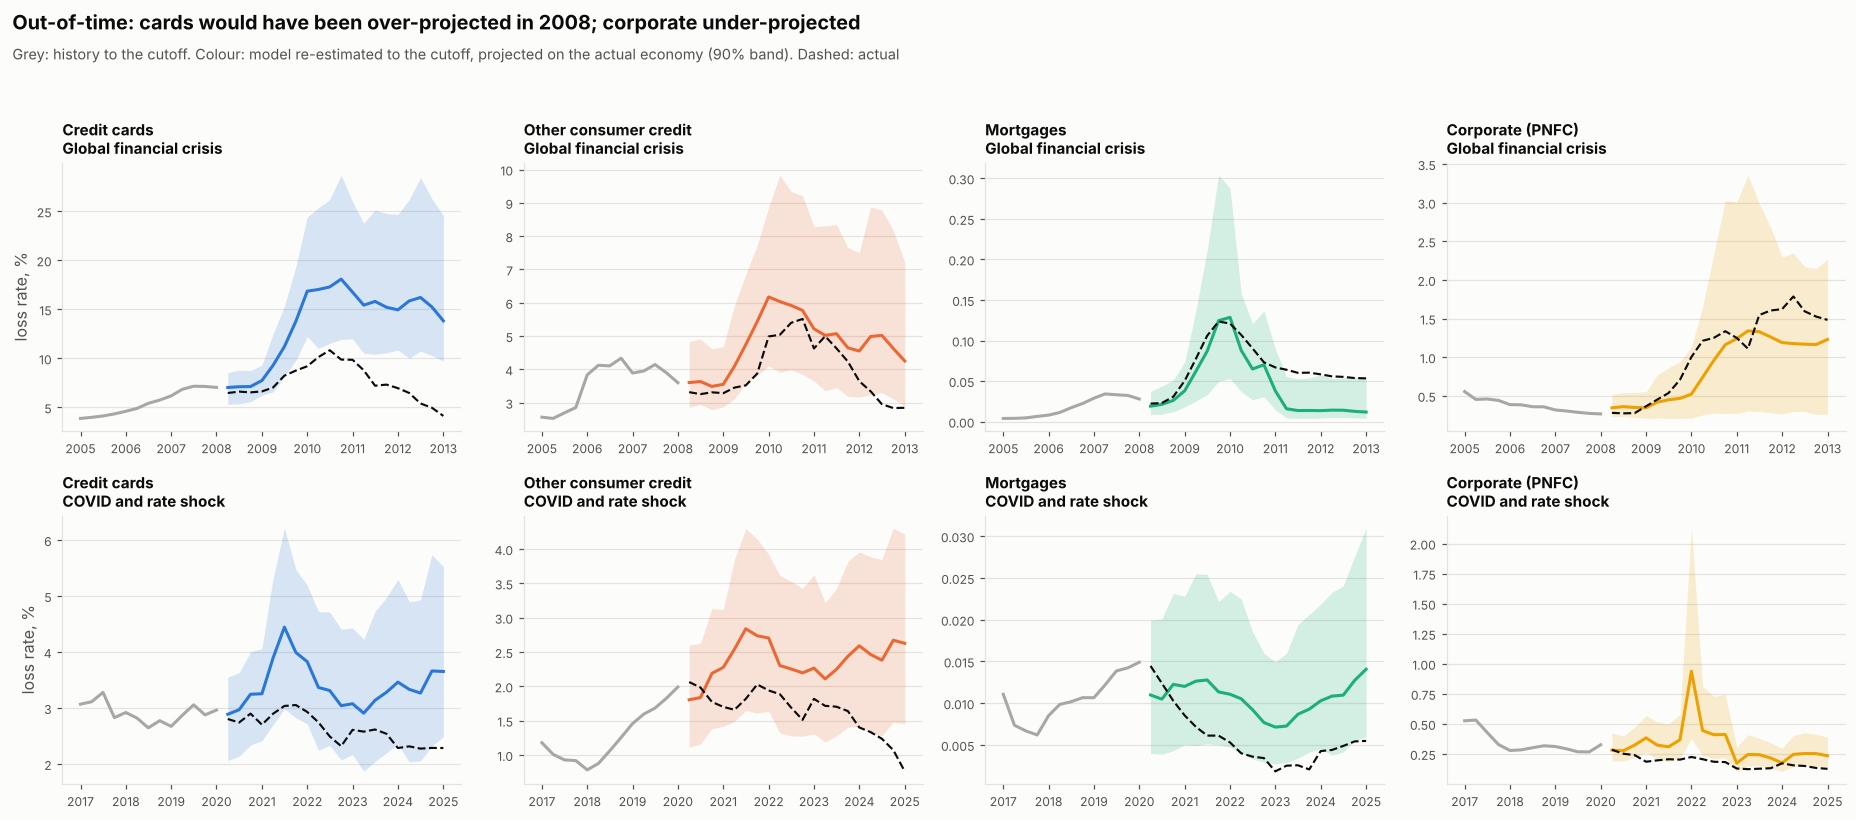

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for j, p in enumerate(PORTFOLIOS):
    for i, w in enumerate(windows):
        ax, pr = axes[i, j], bt[(p, w)]
        t = pr.index.to_timestamp(how="end")
        hist = trailing_loss_rate(panel, p).loc[pd.Period(windows[w]) - 12: pd.Period(windows[w])]
        ax.plot(hist.index.to_timestamp(how="end"), hist, color=GREY)
        ax.fill_between(t, pr.p05, pr.p95, color=PORTFOLIO_COLOURS[p], alpha=0.18, lw=0)
        ax.plot(t, pr.central, color=PORTFOLIO_COLOURS[p], lw=2)
        ax.plot(t, pr.actual, color="#0b0b0b", lw=1.4, ls="--")
        ax.set_title(f"{LABEL[p]}\n{w}", fontsize=10, pad=6)
        ax.tick_params(labelsize=8)
axes[0, 0].set_ylabel("loss rate, %")
axes[1, 0].set_ylabel("loss rate, %")
fig_title(fig, "Out-of-time: cards would have been over-projected in 2008; corporate under-projected",
          "Grey: history to the cutoff. Colour: model re-estimated to the cutoff, projected on the actual economy (90% band). Dashed: actual")
save(fig, "06_backtests")
fig

**Reading:** in the COVID window, the corporate model re-estimated to 2019 Q4 spikes in 2022. It reacts six quarters later to the 2020 GDP collapse, which furlough and government-backed loans prevented from turning into insolvencies. Without the COVID quarters in its sample, it cannot know that. That is why the champions carry a COVID-regime control.

## 2. Live monitoring: the quarters since the jump-off
The 2025 scenario starts from 2024 Q4. Six quarters of actual data now exist. Re-estimated to 2024 Q4 and projected on the *actual* 2025–26 economy (unemployment rose from 4.4% to about 5%), how did each model do?

In [4]:
live = {p: backtest(champions[p].spec, panel, macro, "2024Q4", horizon=6, n_sims=500) for p in PORTFOLIOS}
mon = pd.DataFrame({LABEL[p]: {"actual 2026Q2 %": pr.actual.iloc[-1], "model 2026Q2 %": pr.central.iloc[-1],
                               "90% band": f"{pr.p05.iloc[-1]:.2f}–{pr.p95.iloc[-1]:.2f}",
                               "inside band": bool(pr.p05.iloc[-1] <= pr.actual.iloc[-1] <= pr.p95.iloc[-1]),
                               "mean error, pp": (pr.central - pr.actual).mean()} for p, pr in live.items()}).T
mon

,actual 2026Q2 %,model 2026Q2 %,90% band,inside band,"mean error, pp"
Credit cards,2.387,3.78,2.56–5.08,False,0.891
Other consumer credit,0.81,1.911,1.11–3.26,False,0.642
Mortgages,0.01,0.02,0.01–0.05,True,0.006
Corporate (PNFC),0.154,0.241,0.16–0.38,False,0.045


**Reading:** the consumer models over-predict the 2025–26 quarters. Unemployment rose by about 0.8 percentage points, and historically that pushed card and personal-loan losses up within a year, but losses stayed flat. That is consistent with the Bank of England's own judgement in the 2025 test: it reviewed recent evidence on consumer credit quality and allowed for lower consumer losses than in past exercises (removing past judgements cut the five-year unsecured impairment rate by an estimated 4.6 percentage points; *Financial Stability Report*, December 2025, Box E). Tighter affordability rules since 2018 (FCA persistent-debt rules) and pandemic-era credit tightening plausibly made today's books less sensitive than the 1995–2019 history. **Implication:** the champion consumer projections are likely conservative for current books; this is quantified as a post-model adjustment in notebook 07.

## 3. Rolling-origin forecasts against a naive benchmark
From every second quarter between 2003 and 2024, re-estimate, forecast eight quarters ahead, and compare with the no-change forecast ("losses stay at today's level").

In [5]:
cutoffs = [str(q) for q in pd.period_range("2003Q4", "2024Q2", freq="Q")[::2]]
ro = {}
for p in PORTFOLIOS:
    ro[(p, "champion")] = rolling_origin(champions[p].spec, panel, macro, cutoffs)
    if p in challengers:
        ro[(p, "challenger")] = rolling_origin(challengers[p].spec, panel, macro, cutoffs)
rows = {}
for (p, m), r in ro.items():
    rows[(LABEL[p], m)] = {"origins": len(r), "RMSE model, pp": np.sqrt((r["model error"] ** 2).mean()),
                           "RMSE naive, pp": np.sqrt((r["naive error"] ** 2).mean()),
                           "bias model, pp": r["model error"].mean()}
rot = pd.DataFrame(rows).T
rot["skill vs naive (1 − RMSE ratio)"] = 1 - rot["RMSE model, pp"] / rot["RMSE naive, pp"]
rot.round(3)

origins  RMSE model, pp  RMSE naive, pp  bias model, pp  skill vs naive (1 − RMSE ratio)
Credit cards          champion       42.0           2.285           1.958           0.851                           -0.167
                      challenger     42.0           2.206           1.958           1.179                           -0.127
Other consumer credit champion       42.0           0.958           1.086           0.516                            0.118
                      challenger     42.0           1.416           1.086           0.132                           -0.304
Mortgages             champion       42.0           0.020           0.029          -0.010                            0.295
                      challenger     42.0           0.028           0.029          -0.016                            0.010
Corporate (PNFC)      champion       42.0           0.249           0.412          -0.031                            0.395
                      challenger     42.0           0.298           0.412          -0.115                            0.277

**Reading:** the corporate (skill +0.40), mortgage (+0.30) and other-consumer (+0.12) champions beat the no-change forecast eight quarters ahead. **The card champion does not (−0.17)**: it over-predicts on average by 0.85 percentage points, mainly because models estimated before 2009 over-shoot the crisis (section 1). Positive skill means the model beats "no change". In a benign period no-change is hard to beat; the value of a satellite model is in turning points, which the crisis windows of section 1 test directly.

## 4. Selection-honest backtest: would the 2007 process have picked a good model?
Sections 1–3 re-estimate the *champion's* drivers, which were chosen with hindsight on the full sample. A stricter test re-runs the whole selection procedure on pre-2008 data only (dynamic models, up to two drivers), then projects through the crisis.

In [6]:
res07 = search("credit_card", panel, macro, max_terms=2, end="2007Q4")
spec07 = res07[res07.passes].iloc[0].spec if res07.passes.any() else res07[res07.sign_ok].sort_values("bic").iloc[0].spec
pr07 = backtest(spec07, panel, macro, "2007Q4", horizon=20, n_sims=500)
print(f"Specification the 2007 procedure would have chosen: {spec07.describe()}  "
      f"({int(res07.passes.sum())} models passed every rule on pre-2008 data)")
pd.DataFrame({"selection with hindsight (champion drivers)": summary(bt[("credit_card", "Global financial crisis")]),
              "selection-honest (2007 procedure)": summary(pr07)}).round(2)

Specification the 2007 procedure would have chosen: unemployment_chg_yoy[t-4] + bank_rate_chg_yoy[t-8] + y[t-4]  (13 models passed every rule on pre-2008 data)


,selection with hindsight (champion drivers),selection-honest (2007 procedure)
actual peak %,10.83,10.83
model peak %,18.08,15.68
"peak error, pp",7.26,4.86
"RMSE, pp",6.90,5.26
"mean error, pp (+ = over-predicts)",6.02,4.39
share of quarters inside 90% band,0.30,0.30


## 5. Block bootstrap of the coefficients
Resample blocks of eight consecutive quarters of (y, X) rows with replacement, refit, and repeat 1,000 times. Blocks preserve the residual autocorrelation that the trailing target creates. If bootstrap intervals are similar to the Newey–West intervals, the analytic standard errors can be trusted.

In [7]:
rng = np.random.default_rng(42)
boot_rows = {}
for p in PORTFOLIOS:
    y, X = sample(champions[p].spec, target(panel, p), macro)
    n, block = len(y), 8
    draws = []
    for _ in range(1000):
        starts = rng.integers(0, n - block + 1, int(np.ceil(n / block)))
        idx = np.concatenate([np.arange(s, s + block) for s in starts])[:n]
        draws.append(np.linalg.lstsq(X.values[idx], y.values[idx], rcond=None)[0])
    draws = pd.DataFrame(draws, columns=X.columns)
    fm = champions[p]
    for c in X.columns:
        if c in ("const", "covid"):
            continue
        se = np.sqrt(fm.cov.loc[c, c])
        boot_rows[(LABEL[p], c)] = {"coef": fm.params[c], "HAC 95% low": fm.params[c] - 1.96 * se,
                                    "HAC 95% high": fm.params[c] + 1.96 * se,
                                    "bootstrap 95% low": draws[c].quantile(.025), "bootstrap 95% high": draws[c].quantile(.975),
                                    "bootstrap share with correct sign": (np.sign(draws[c]) == np.sign(fm.params[c])).mean()}
pd.DataFrame(boot_rows).T.round(3)

coef  HAC 95% low  HAC 95% high  bootstrap 95% low  bootstrap 95% high  bootstrap share with correct sign
Credit cards          unemployment_chg_yoy_L2    0.148        0.071         0.226              0.057               0.231                              0.999
                      bank_rate_L8               0.030        0.009         0.050              0.013               0.060                              0.996
                      y_L4                       0.874        0.770         0.979              0.698               0.975                              1.000
Other consumer credit unemployment_chg_yoy_L2    0.111        0.010         0.213             -0.030               0.250                              0.951
                      y_L4                       0.858        0.649         1.068              0.562               1.095                              1.000
Mortgages             unemployment_L2            0.229        0.055         0.403              0.084               0.499                              0.998
                      house_price_growth_yoy_L1 -0.035       -0.058        -0.012             -0.064              -0.004                              0.981
                      bank_rate_L8               0.097        0.038         0.156              0.031               0.184                              0.997
                      y_L4                       0.522        0.291         0.752              0.222               0.750                              1.000
Corporate (PNFC)      unemployment_L0            0.209        0.134         0.284              0.080               0.289                              1.000
                      gdp_growth_yoy_L6         -0.023       -0.032        -0.013             -0.056              -0.014                              0.997
                      y_L4                       0.615        0.486         0.743              0.453               0.792                              1.000

## 6. Quantile regression: are bad quarters more sensitive?
OLS models the *mean*. A stress test cares about the tail. Quantile regression estimates the effect of each driver on the 50th, 75th and 90th percentiles of card losses.

In [8]:
y, X = sample(champions["credit_card"].spec, target(panel, "credit_card"), macro)
qrows = {}
for q in [0.5, 0.75, 0.9]:
    r = sm.QuantReg(y, X).fit(q=q, max_iter=5000)
    qrows[f"q = {q}"] = r.params.drop(["const"])
qrows["OLS (mean)"] = champions["credit_card"].params.drop(["const"])
qt = pd.DataFrame(qrows).T
qt

,unemployment_chg_yoy_L2,bank_rate_L8,covid,y_L4
q = 0.5,0.164,0.020,-0.116,0.842
q = 0.75,0.147,0.027,-0.131,0.902
q = 0.9,0.197,0.018,-0.227,0.887
OLS (mean),0.148,0.030,-0.057,0.874


In [9]:
tail_paths = {}
for q in [0.5, 0.9]:
    r = sm.QuantReg(y, X).fit(q=q, max_iter=5000)
    fm_q = champions["credit_card"].__class__(champions["credit_card"].spec, r.params, champions["credit_card"].cov,
                                              champions["credit_card"].resid, int(r.nobs), 0, 0, 0, ("", ""))
    tail_paths[f"quantile {q}"] = project(fm_q, target(panel, "credit_card"), path).central
tail_paths["OLS champion"] = project(champions["credit_card"], target(panel, "credit_card"), path).central
tp = pd.DataFrame(tail_paths)
pd.DataFrame({"peak card loss under scenario, %": tp.max(), "5-year cumulative, %": tp.apply(cumulative_rate)}).round(2)

,"peak card loss under scenario, %","5-year cumulative, %"
quantile 0.5,6.81,25.54
quantile 0.9,11.83,40.44
OLS champion,6.37,24.36


**Caution on the 90th-percentile path:** projecting recursively with 90th-percentile coefficients places *every* quarter at its 90th percentile, a far more extreme path than "the 90th-percentile outcome". It is an upper bound on tail sensitivity, not a forecast. The useful finding is the coefficient table: the unemployment effect at the 90th percentile (0.20) is about a third larger than at the mean (0.15), so bad quarters are somewhat more sensitive to the labour market.

## 7. Sensitivity analysis: which driver matters most?
Each driver's scenario path is shifted for the whole five years by a fixed shock, all else equal. Effect on the five-year cumulative loss rate.

In [10]:
shocks = {"unemployment +1pp": ("unemployment", 1.0), "Bank Rate +1pp": ("bank_rate", 1.0),
          "house prices −5pp y/y": ("house_price_growth_yoy", -5.0), "GDP growth −1pp y/y": ("gdp_growth_yoy", -1.0)}
base_cum = {p: cumulative_rate(project(champions[p], target(panel, p), path).central) for p in PORTFOLIOS}
sens = {}
for name, (col, size) in shocks.items():
    shocked = path.copy()
    shocked.loc[shocked.index > JUMP_OFF, col] += size
    shocked["unemployment_chg_yoy"] = shocked["unemployment"].diff(4)
    shocked["bank_rate_chg_yoy"] = shocked["bank_rate"].diff(4)
    sens[name] = {LABEL[p]: cumulative_rate(project(champions[p], target(panel, p), shocked).central) - base_cum[p]
                  for p in PORTFOLIOS}
sens = pd.DataFrame(sens)
sens.insert(0, "base 5-year cumulative %", [base_cum[p] for p in PORTFOLIOS])
sens.round(3)

,base 5-year cumulative %,unemployment +1pp,Bank Rate +1pp,house prices −5pp y/y,GDP growth −1pp y/y
Credit cards,24.357,2.731,0.872,0.0,0.000
Other consumer credit,7.048,0.591,0.000,0.0,0.000
Mortgages,0.532,0.275,0.063,0.2,0.000
Corporate (PNFC),3.645,1.909,0.000,0.0,0.139


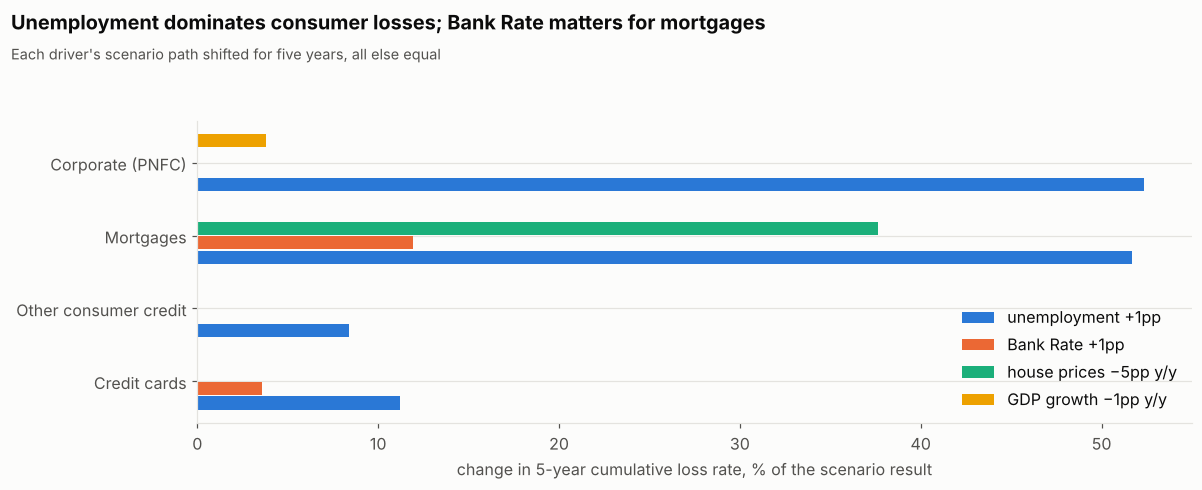

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.5))
rel = sens.drop(columns="base 5-year cumulative %").div(sens["base 5-year cumulative %"], axis=0) * 100
width = 0.2
for i, col in enumerate(rel.columns):
    ax.barh(np.arange(len(rel)) + (i - 1.5) * width, rel[col], height=width * 0.9,
            color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"][i], label=col)
ax.set_yticks(range(len(rel)), rel.index)
ax.axvline(0, color=GREY, lw=1)
ax.set_xlabel("change in 5-year cumulative loss rate, % of the scenario result")
ax.legend(loc="lower right")
fig_title(fig, "Unemployment dominates consumer losses; Bank Rate matters for mortgages",
          "Each driver's scenario path shifted for five years, all else equal")
save(fig, "06_sensitivity")
fig

## 8. Challenger models under the 2025 scenario

In [12]:
rows = {}
for p in PORTFOLIOS:
    y = target(panel, p)
    for name, m in [("champion", champions.get(p)), ("challenger", challengers.get(p)), ("pooled consumer panel", panel_ch.get(p))]:
        if m is None:
            continue
        pr = project(m, y, path).central
        rows[(LABEL[p], name)] = {"model": m.spec.describe(), "peak %": pr.max(), "5-year cumulative %": cumulative_rate(pr)}
chal = pd.DataFrame(rows).T
chal

model peak % 5-year cumulative %
Credit cards          champion                                 unemployment_chg_yoy[t-2] + bank_rate[t-8] + y[t-4]  6.367              24.357
                      challenger                                                unemployment_chg_yoy[t-2] + y[t-4]  6.078              22.401
Other consumer credit champion                                                  unemployment_chg_yoy[t-2] + y[t-4]  2.368               7.048
                      challenger                                                           bank_rate[t-8] + y[t-4]  2.084               6.321
                      pooled consumer panel                    unemployment_chg_yoy[t-2] + bank_rate[t-8] + y[t-4]  3.173               9.272
Mortgages             champion               unemployment[t-2] + house_price_growth_yoy[t-1] + bank_rate[t-8] +...  0.224               0.532
                      challenger                 unemployment[t-2] + gdp_growth_yoy[t-0] + bank_rate[t-6] + y[t-4]  0.123               0.372
Corporate (PNFC)      champion                                    unemployment[t-0] + gdp_growth_yoy[t-6] + y[t-4]   1.08               3.645
                      challenger                                                        unemployment[t-1] + y[t-4]  1.013               3.422

## Validation conclusions

The rating uses a simple traffic light: **green** fit for use, **amber** fit for use with documented limitations or overlays, **red** not fit for use.

| Portfolio | Evidence | Rating |
|---|---|---|
| **Corporate** | Best forecasting skill (+0.40 vs naive); bootstrap confirms every sign (≥ 99.7%); stays inside its 90% band through the crisis; but under-projects the 2009–12 peak by 0.45 pp (25%) | 🟢 **Green**, with a note that crisis peaks may be understated |
| **Mortgages** | Accurate backtests (peak error 0.01 pp) and skill +0.30; signs robust; but RESET rejects the functional form and the challenger projects about 30% lower | 🟡 **Amber**: immaterial in £ terms; report the champion–challenger range |
| **Credit cards** | Signs robust (≥ 99.6% of bootstraps); but over-projects the 2008 crisis when estimated pre-crisis (by 7.3 pp with hindsight drivers, 4.9 pp with the 2007 selection procedure), over-projects 2025–26, and has negative skill against no-change | 🟡 **Amber, conservative**: fit for stress use, where over-prediction is the safer error; quantify an overlay for current book quality (notebook 07) |
| **Other consumer** | Positive skill (+0.12) but fragile: the bootstrap interval for the unemployment effect includes zero (sign correct in 95%); the pooled consumer panel projects 9.3% cumulative vs 7.0% | 🟡 **Amber, weak**: use the champion-to-panel range; strengthen with more drivers when longer credit-growth history is available |

**Cross-cutting findings**
1. **Model risk is material.** For cards, the transform (notebook 04), the challenger (−8% cumulative) and the tail (quantile) view span a wide range. Notebook 07 reports projections as ranges, not points.
2. **The labour market dominates:** a one-point higher unemployment path adds 2.7 pp to five-year card losses and 1.9 pp to corporate losses (sensitivity table). Bank Rate adds 0.9 pp to cards and is the only driver outside its historical range (notebook 01). That makes the rate channel the single largest extrapolation risk.
3. **Current consumer books look less sensitive than history**, consistent with the Bank of England's 2025 judgement (Box E). Live monitoring should continue each quarter; three more quarters outside the 90% band would trigger re-estimation under the model monitoring policy.